# College Majors 2026: Model 3, Gradient Boosting, and Final Comparison
## Predicting 4-year earnings of bachelor's programs

**Where we are:** Ridge (Model 1) reached test R² 0.744 and the random forest (Model 2) reached 0.786. Both still
under-predict the highest earners.

**Why gradient boosting next:** a random forest builds many trees **independently** and averages them. Gradient boosting
builds trees **one after another, each one focused on fixing the errors left by the trees before it**. That targeted
error-correction is why it is usually the most accurate method on tabular data like ours, and it is a natural candidate for the
high earners the other models miss.

This notebook:
1. Re-fits Ridge and the random forest with their **already-tuned settings** (no re-tuning), so all models sit in one table.
2. Tunes and evaluates **histogram gradient boosting** (scikit-learn's `HistGradientBoostingRegressor`).
3. Produces the **final model comparison** for Section 4 of the report.

All models use the **same preprocessing pipeline**, the **same school-grouped train/test split** and the **same cross-validation folds**.

> **To run:** put `bachelors_model_ready.csv` next to this notebook, then *Run All*. Total run time is about **5–10 minutes**.

## 0. Setup

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 200)
%matplotlib inline

RANDOM_STATE = 42
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, BG = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = PALETTE[:4]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": BG, "axes.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
})
def show(fig, name):
    fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight"); plt.show()

## 1. Load the model-ready data and define features

In [2]:
df = pd.read_csv("bachelors_model_ready.csv", dtype={"opeid6": str, "cip_code_4digit": str})

NUMERIC = [
    "log_awards_avg", "is_main_campus", "outcomes_shared_across_campuses",
    "log_enrollment", "institution_tuition_in_state_usd", "tuition_out_minus_in",
    "institution_admission_rate", "admission_rate_missing", "institution_avg_sat", "sat_missing",
    "institution_is_hbcu", "institution_latitude", "institution_longitude",
    "national_median_earnings_4yr_usd",
    "linked_occupations_count", "occupation_median_wage_2024_usd", "occupation_growth_pct_2024_34",
    "occupation_growth_pct_max", "log_occ_employment",
    "occupations_using_ai_software", "ai_software_occupation_share", "expert_system_occupation_share",
    "ai_tools_max_per_occupation", "hot_technologies_mean_per_occupation", "any_ai_occupation",
]
CATEGORICAL = ["institution_control", "institution_region", "cip_family_title",
               "online", "selectivity", "occupation_typical_entry_education"]
FEATURES = NUMERIC + CATEGORICAL
TARGET = "target_log_earnings_4yr"
GROUP = "opeid6"

train = df[df.split == "train"].reset_index(drop=True)
test = df[df.split == "test"].reset_index(drop=True)
X_train, y_train, g_train = train[FEATURES], train[TARGET], train[GROUP]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}  |  Features: {len(FEATURES)}")

Train: (19932, 31)  |  Test: (5351, 31)  |  Features: 31


## 2. Shared preprocessing and cross-validation

- **Preprocessing** (inside every model's pipeline, fit on training folds only): median-impute and scale numbers; one-hot encode categories.
- **Cross-validation:** `GroupKFold(5)` grouped by institution, so a school is never in both the fitting and validation part of a fold.
  This matches how the test set was built.
- **Tuning metric:** R² on log earnings. Final results are also reported **in dollars**.

In [3]:
def make_preprocess():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=30, sparse_output=False), CATEGORICAL),
    ])

cv = GroupKFold(n_splits=5)
results = {}          # test-set results for each model
cv_scores = {}        # best cross-validated R² for each model

## 3. Baseline: predict the field's national median

The simplest possible prediction, needing no model. Every model must beat it to be worth using.

In [4]:
def evaluate(name, pred_log):
    """Score predictions on the test set, both on log scale and in dollars."""
    actual = np.exp(y_test); pred = np.exp(pred_log)
    results[name] = {
        "R² (log)": r2_score(y_test, pred_log),
        "RMSE ($)": np.sqrt(mean_squared_error(actual, pred)),
        "MAE ($)": mean_absolute_error(actual, pred),
        "Median abs. % error": np.median(np.abs(pred - actual) / actual) * 100,
    }
    return pd.Series(results[name]).round(3)

base_pred = np.log(test["national_median_earnings_4yr_usd"])
evaluate("Baseline (national field median)", base_pred)

R² (log)                   0.566
RMSE ($)               12624.187
MAE ($)                 8760.366
Median abs. % error       10.413
dtype: float64

## 4. Model 1 (Ridge), re-fit with its tuned setting

`alpha = 3.16`, chosen in the Ridge notebook by grouped 5-fold cross-validation (CV R² 0.753).

In [5]:
t = time.time()
ridge = Pipeline([("prep", make_preprocess()), ("model", Ridge(alpha=3.16))])
ridge.fit(X_train, y_train)
cv_scores["Ridge regression"] = 0.753   # from the Ridge notebook's tuning
print(f"Fitted in {time.time() - t:.1f}s")
evaluate("Ridge regression", ridge.predict(X_test))

Fitted in 0.1s


R² (log)                   0.744
RMSE ($)               10005.001
MAE ($)                 7029.736
Median abs. % error        8.581
dtype: float64

## 5. Model 2 (random forest), re-fit with its tuned setting

200 trees, no depth limit, `min_samples_leaf = 5`, `max_features = 0.3`, chosen in the random forest notebook (CV R² 0.789).

In [6]:
t = time.time()
rf = Pipeline([("prep", make_preprocess()),
               ("model", RandomForestRegressor(n_estimators=200, max_depth=None, min_samples_leaf=5, max_features=0.3,
                                               n_jobs=-1, random_state=RANDOM_STATE))])
rf.fit(X_train, y_train)
cv_scores["Random forest"] = 0.789   # from the random forest notebook's tuning
print(f"Fitted in {time.time() - t:.1f}s")
evaluate("Random forest", rf.predict(X_test))

Fitted in 4.9s


R² (log)                  0.786
RMSE ($)               8913.602
MAE ($)                6231.992
Median abs. % error       7.573
dtype: float64

## 6. Model 3: Histogram gradient boosting

**Why we use it:** gradient boosting is usually the most accurate method on tabular data, and it attacks errors directly,
which suits the high-earner problem the other two models have.

**How it works, step by step:**
1. Start with a simple prediction for every program: the average log earnings.
2. Compute each program's **error (residual)**: actual minus predicted.
3. Fit a **small tree to those errors**, so it learns where the current model is too high or too low.
4. Add that tree's predictions to the model, but **shrunk by the `learning_rate`** (e.g. 0.05 = take 5% of the correction), so no single tree
   dominates.
5. Repeat hundreds of times. Each new tree fixes what's left over.

**Boosting vs. random forest:** a forest grows deep trees independently and averages them, which reduces variance. Boosting grows
small trees in sequence, each fixing the last, which reduces bias. That's why it can push further on hard cases.

**"Histogram":** numeric features are grouped into at most 255 bins before splitting, which makes training much faster on 20k rows.

**Early stopping:** 10% of the training data is held aside inside each fit. Training stops when 30 trees in a row fail to improve it,
so the number of trees is chosen automatically and the model doesn't keep fitting noise.

**Tuning** (randomized search, 10 combinations × 5 folds):
| Hyperparameter | Candidates | Why |
|---|---|---|
| `learning_rate` | 0.03, 0.05, 0.1 | Size of each correction step; smaller = slower but often more accurate |
| `max_leaf_nodes` | 15, 31, 63 | Complexity of each tree |
| `min_samples_leaf` | 20, 50, 100 | Minimum programs per leaf (regularization) |
| `l2_regularization` | 0, 1, 5 | Penalty on leaf values (regularization) |

In [7]:
hgb = Pipeline([("prep", make_preprocess()),
                ("model", HistGradientBoostingRegressor(max_iter=3000, early_stopping=True, n_iter_no_change=30,
                                                        validation_fraction=0.1, random_state=RANDOM_STATE))])
hgb_grid = {"model__learning_rate": [0.03, 0.05, 0.1],
            "model__max_leaf_nodes": [15, 31, 63],
            "model__min_samples_leaf": [20, 50, 100],
            "model__l2_regularization": [0, 1, 5]}

t = time.time()
hgb_search = RandomizedSearchCV(hgb, hgb_grid, n_iter=10, cv=cv, scoring="r2", random_state=RANDOM_STATE,
                                n_jobs=-1, return_train_score=True)
hgb_search.fit(X_train, y_train, groups=g_train)
print(f"Done in {time.time() - t:.0f}s | best = {hgb_search.best_params_} | CV R² = {hgb_search.best_score_:.3f}")
print("Trees used by best model (early stopping):", hgb_search.best_estimator_.named_steps["model"].n_iter_)
cv_scores["Gradient boosting"] = hgb_search.best_score_

cols = ["param_model__learning_rate", "param_model__max_leaf_nodes", "param_model__min_samples_leaf",
        "param_model__l2_regularization", "mean_train_score", "mean_test_score"]
display(pd.DataFrame(hgb_search.cv_results_)[cols].sort_values("mean_test_score", ascending=False)
        .rename(columns=lambda c: c.replace("param_model__", "").replace("mean_test_score", "CV R²")
                .replace("mean_train_score", "Train R²")).round(3).reset_index(drop=True))
evaluate("Gradient boosting", hgb_search.predict(X_test))

Done in 158s | best = {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 31, 'model__learning_rate': 0.03, 'model__l2_regularization': 1} | CV R² = 0.788
Trees used by best model (early stopping): 940


,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,Train R²,CV R²
0,0.03,31,20,1,0.882,0.788
1,0.05,31,20,0,0.890,0.786
2,0.03,31,50,1,0.880,0.786
3,0.03,15,20,0,0.869,0.786
4,0.05,63,50,5,0.899,0.786
5,0.03,15,50,1,0.862,0.785
6,0.03,31,50,0,0.885,0.785
7,0.05,15,50,0,0.871,0.785
8,0.10,31,50,0,0.879,0.783
9,0.10,15,20,0,0.879,0.783


R² (log)                  0.783
RMSE ($)               8956.756
MAE ($)                6314.174
Median abs. % error       7.722
dtype: float64

**Reading the tuning table:**
- **Best setting:** `learning_rate = 0.03`, `max_leaf_nodes = 31`, `min_samples_leaf = 20`, `l2_regularization = 1` → **CV R² 0.788**.
- **All 10 settings land between 0.783 and 0.788**, so gradient boosting is **not very sensitive** to these choices on our data. The
  fastest learning rate (0.1) is slightly worse; smaller steps with more trees work best, as boosting theory suggests.
- **Train R² 0.882 vs CV R² 0.788:** a similar gap to the random forest. CV and test R² (0.783) agree, so it generalizes to unseen schools.
- **Number of trees:** early stopping chose about 910 trees. Raising the cap from 1,000 to 3,000 gave the same result, so it stopped
  because the model stopped improving, not because it hit a limit.

### 6.1 Learning curve: how early stopping picked the number of trees

Each point is the model after adding one more tree. The **training loss** keeps falling as trees are added. The **internal validation loss**
(the 10% held aside) flattens out; when it stops improving for 30 trees, training stops. This is how boosting avoids overfitting.

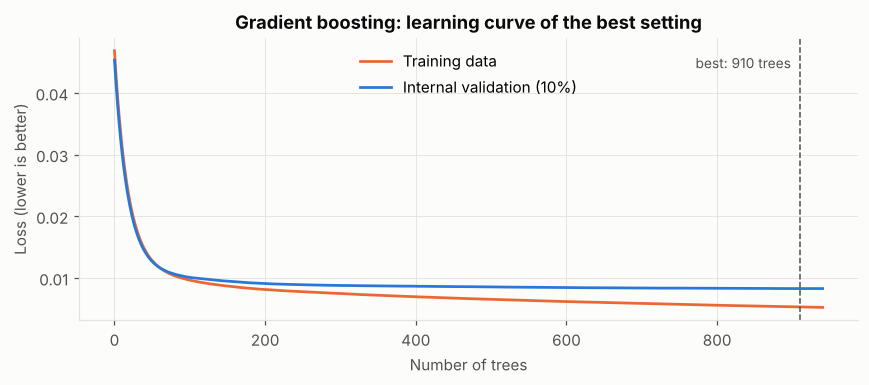

In [8]:
m = hgb_search.best_estimator_.named_steps["model"]
train_loss, val_loss = -m.train_score_, -m.validation_score_   # stored as negative loss (squared error / 2, log scale)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(train_loss, color=ORANGE, linewidth=1.8, label="Training data")
ax.plot(val_loss, color=BLUE, linewidth=1.8, label="Internal validation (10%)")
best_it = int(np.argmin(val_loss))
ax.axvline(best_it, color=INK2, linestyle="--", linewidth=1)
ax.text(best_it - 12, ax.get_ylim()[1] * 0.9, f"best: {best_it} trees", color=INK2, fontsize=9, ha="right")
ax.set(xlabel="Number of trees", ylabel="Loss (lower is better)", title="Gradient boosting: learning curve of the best setting")
ax.legend(frameon=False)
show(fig, "m3_hgb_learning_curve.png")

## 7. Final model comparison

**Metrics (same for every model):**
- **R² (log scale):** share of variation in log earnings explained (1 = perfect). Matches what the models were trained on.
- **RMSE ($):** typical error in dollars; punishes big misses more.
- **MAE ($):** average absolute error in dollars; easiest to explain ("off by $X on average").
- **Median abs. % error:** typical error as a percentage of the program's actual earnings.

**CV R²** is from tuning on the training data; the other columns are from the untouched **test set** (360 institutions none of the models has seen).

In [9]:
comp = pd.DataFrame(results).T
comp.insert(0, "CV R² (train)", pd.Series(cv_scores))
comp_fmt = comp.copy()
for c in ["RMSE ($)", "MAE ($)"]: comp_fmt[c] = comp[c].map("${:,.0f}".format)
comp_fmt["Median abs. % error"] = comp["Median abs. % error"].map("{:.1f}%".format)
for c in ["CV R² (train)", "R² (log)"]: comp_fmt[c] = comp[c].map(lambda v: "—" if pd.isna(v) else f"{v:.3f}")
comp_fmt

,CV R² (train),R² (log),RMSE ($),MAE ($),Median abs. % error
Baseline (national field median),—,0.566,"$12,624","$8,760",10.4%
Ridge regression,0.753,0.744,"$10,005","$7,030",8.6%
Random forest,0.789,0.786,"$8,914","$6,232",7.6%
Gradient boosting,0.788,0.783,"$8,957","$6,314",7.7%


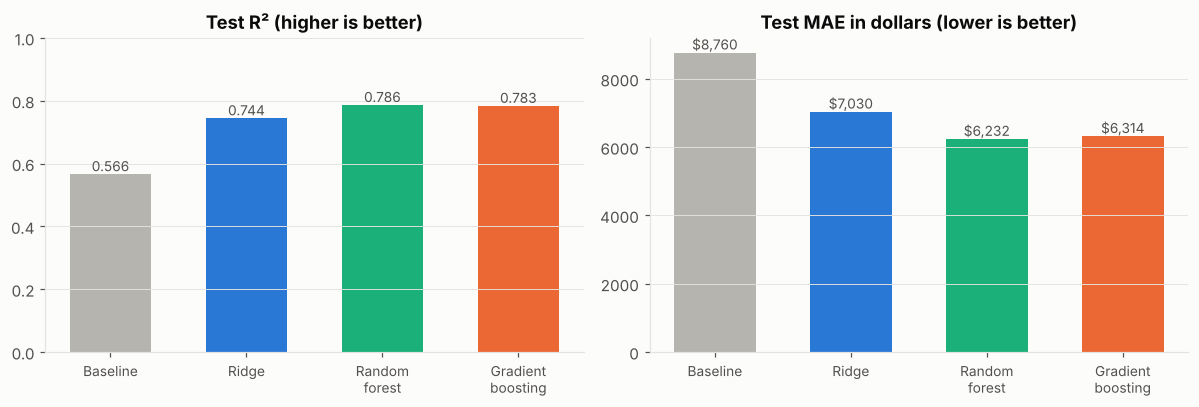

In [10]:
colors = ["#b5b4ae", BLUE, AQUA, ORANGE]
short = ["Baseline", "Ridge", "Random\nforest", "Gradient\nboosting"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
vals = comp["R² (log)"].values
axes[0].bar(short, vals, color=colors, width=0.6)
for x, v in enumerate(vals): axes[0].text(x, v + 0.01, f"{v:.3f}", ha="center", fontsize=9, color=INK2)
axes[0].set(title="Test R² (higher is better)", ylim=(0, 1)); axes[0].grid(axis="x", visible=False)
vals = comp["MAE ($)"].values
axes[1].bar(short, vals, color=colors, width=0.6)
for x, v in enumerate(vals): axes[1].text(x, v + 100, f"${v:,.0f}", ha="center", fontsize=9, color=INK2)
axes[1].set(title="Test MAE in dollars (lower is better)"); axes[1].grid(axis="x", visible=False)
for a in axes: a.tick_params(axis="x", labelsize=9)
show(fig, "m3_final_model_comparison.png")

### 7.1 Best model: predicted vs. actual

Best model on test set: Random forest


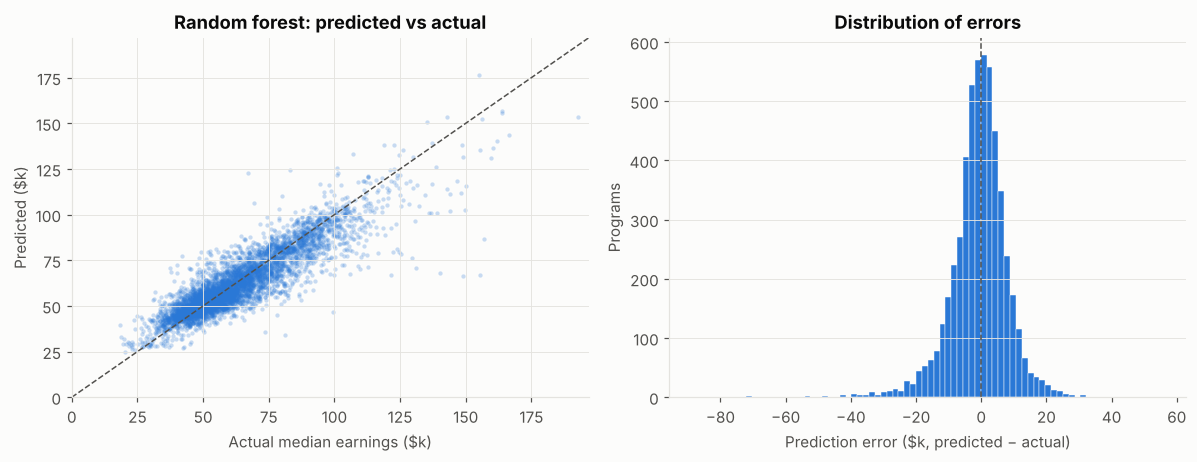

,Within ±10%,Within ±20%
Ridge,56%,85%
Random forest,61%,88%
Gradient boosting,61%,88%


In [11]:
best_name = comp.drop(index="Baseline (national field median)")["R² (log)"].idxmax()
best = {"Ridge regression": ridge, "Random forest": rf, "Gradient boosting": hgb_search}[best_name]
pred = np.exp(best.predict(X_test)); actual = np.exp(y_test)
print("Best model on test set:", best_name)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].scatter(actual / 1000, pred / 1000, s=8, alpha=0.25, color=BLUE, linewidths=0)
lim = [0, max(actual.max(), pred.max()) / 1000 * 1.02]
axes[0].plot(lim, lim, color=INK2, linestyle="--", linewidth=1)
axes[0].set(xlim=lim, ylim=lim, xlabel="Actual median earnings ($k)", ylabel="Predicted ($k)",
            title=f"{best_name}: predicted vs actual")
err = (pred - actual) / 1000
axes[1].hist(err, bins=80, color=BLUE, edgecolor=BG, linewidth=0.3)
axes[1].axvline(0, color=INK2, linestyle="--", linewidth=1)
axes[1].set(xlabel="Prediction error ($k, predicted − actual)", ylabel="Programs", title="Distribution of errors")
axes[1].grid(axis="x", visible=False)
show(fig, "m3_best_pred_vs_actual.png")
preds = {"Ridge": np.exp(ridge.predict(X_test)), "Random forest": np.exp(rf.predict(X_test)),
         "Gradient boosting": np.exp(hgb_search.predict(X_test))}
within = pd.DataFrame({k: {"Within ±10%": (np.abs(p - actual) / actual <= 0.10).mean(),
                           "Within ±20%": (np.abs(p - actual) / actual <= 0.20).mean()} for k, p in preds.items()}).T
within.style.format("{:.0%}")

### 7.2 The high-earner problem: average error by earnings level

Both earlier models under-predicted the highest earners. This compares the average signed error (predicted − actual) of all three
models within groups of actual earnings. Zero = no systematic bias; negative = predicting too low.

,Ridge,Random forest,Gradient boosting,Programs
band,,,,
<$40k,"$7,231","$6,388","$6,080",333
$40–60k,"$1,890","$1,613","$1,539",2562
$60–80k,"$-1,643","$-2,066","$-1,896",1495
$80–100k,"$-4,423","$-4,642","$-4,608",703
$100–150k,"$-13,408","$-12,549","$-11,639",245
$150k+,"$-39,796","$-26,747","$-24,047",13


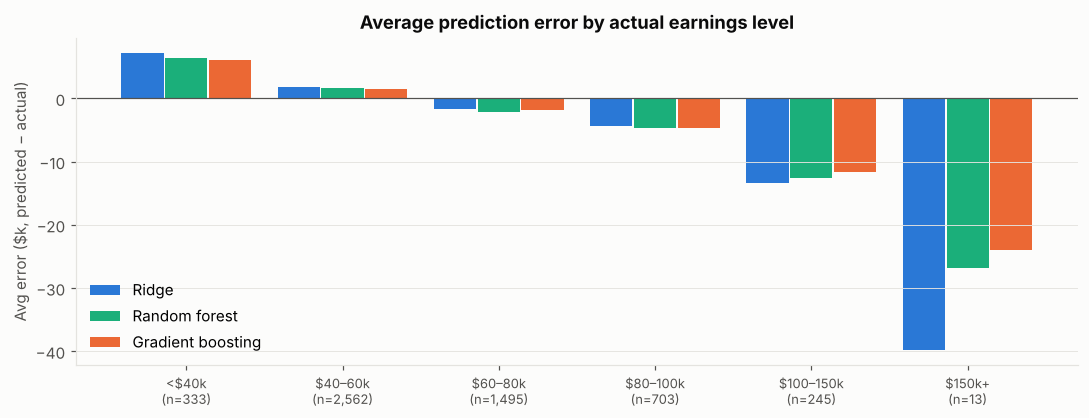

In [12]:
bands = pd.cut(actual, [0, 40e3, 60e3, 80e3, 100e3, 150e3, np.inf],
               labels=["<$40k", "$40–60k", "$60–80k", "$80–100k", "$100–150k", "$150k+"])
bias = pd.DataFrame({k: p - actual for k, p in preds.items()}).assign(band=bands.values)
by_band = bias.groupby("band", observed=True).mean()
counts = bias.groupby("band", observed=True).size()
display(by_band.map(lambda v: f"${v:,.0f}").assign(Programs=counts.values))

fig, ax = plt.subplots(figsize=(10, 3.9))
x = np.arange(len(by_band)); w = 0.27
for j, (k, col) in enumerate(zip(by_band.columns, [BLUE, AQUA, ORANGE])):
    ax.bar(x + (j - 1) * (w + 0.01), by_band[k] / 1000, w, color=col, label=k)
ax.axhline(0, color=INK2, linewidth=0.8)
ax.set_xticks(x, [f"{b}\n(n={n:,})" for b, n in zip(by_band.index, counts.values)], fontsize=8.5)
ax.set(ylabel="Avg error ($k, predicted − actual)", title="Average prediction error by actual earnings level")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
show(fig, "m3_error_by_earnings_band_all_models.png")

**What this shows:**
- **Gradient boosting has the smallest bias for high earners:** about −$11.6k for $100–150k programs (forest −$12.5k, Ridge −$13.4k)
  and −$24k for $150k+ (forest −$27k, Ridge −$40k). Its error-correcting design helps a little, as expected.
- But **all three models share the same pattern**: too high for low earners, too low for high earners. This is regression toward the middle,
  because extreme programs are rare.
- Since three very different methods hit the same wall, the limit is probably **the information in our features**, not the model. Something that
  makes a top program exceptional (e.g. a specific school's reputation in a specific field) isn't captured by our 31 predictors.

### 7.3 Which features does gradient boosting rely on? (permutation importance)

**Permutation importance:** shuffle one feature's values in the test set and measure how much R² drops.
A big drop means the model relies on that feature. It works the same way for any model, so it can be compared directly with the Ridge and random forest charts in their notebooks.

Computed in 17s


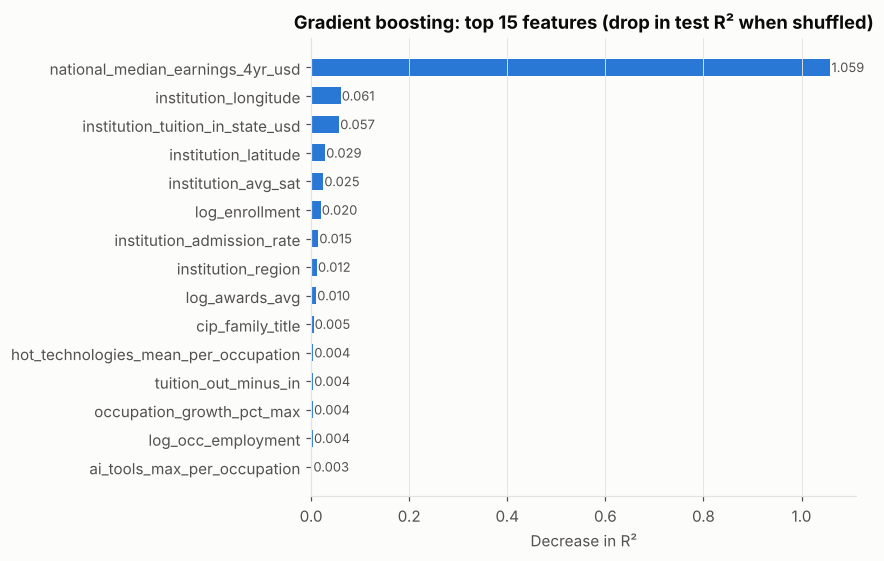

In [13]:
t = time.time()
pi = permutation_importance(hgb_search.best_estimator_, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
print(f"Computed in {time.time() - t:.0f}s")

top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
for i, v in enumerate(top.values): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8.5, color=INK2)
ax.set(title="Gradient boosting: top 15 features (drop in test R² when shuffled)", xlabel="Decrease in R²")
ax.grid(axis="y", visible=False)
show(fig, "m3_best_permutation_importance.png")

## 8. Summary and model choice

In [14]:
b = comp.loc["Baseline (national field median)"]; m = comp.loc[best_name]
print(f"Best model: {best_name}")
print(f"  Test R² {m['R² (log)']:.3f} vs baseline {b['R² (log)']:.3f}  "
      f"(+{m['R² (log)'] - b['R² (log)']:.3f})")
print(f"  MAE ${m['MAE ($)']:,.0f} vs baseline ${b['MAE ($)']:,.0f}  "
      f"({(1 - m['MAE ($)'] / b['MAE ($)']):.0%} smaller)")
print(f"  Gradient boosting top 5 features: {', '.join(imp.index[:5])}")

Best model: Random forest
  Test R² 0.786 vs baseline 0.566  (+0.220)
  MAE $6,232 vs baseline $8,760  (29% smaller)
  Gradient boosting top 5 features: national_median_earnings_4yr_usd, institution_longitude, institution_tuition_in_state_usd, institution_latitude, institution_avg_sat


### Takeaways for the report


- **All three models beat the baseline**, so school, location, job-market and AI-exposure features add real information beyond "which field is it".
- **Random forest and gradient boosting are effectively tied**: the gap is 0.003 R² and $82 MAE, well within normal variation. Both predict
  61% of programs within ±10%.
- **Model choice: random forest.** It's marginally best on both CV (0.789) and test, has fewer settings to tune, and its results were stable across
  settings. Gradient boosting is a close second and slightly better for the highest earners.
- **Generalization:** CV and test R² agree for every model, so the school-grouped split worked and the results should hold for new schools.
- **What drives earnings:** the field's national median dominates in every model, followed by school location, SAT/selectivity and tuition.
- **Limitation:** every model under-predicts the very top earners; more informative features, not a different algorithm, would be needed to fix that.